# Основные подходы машинного бучения

1. Supervised leanring (Обучение с преподавателем)

    - Regression
    - Classification

2. Unsupervised leanring (Обучение без преподавателя)

    - Clustering
    - Dimensionality Reduction
    - Anomaly detection

3. Reinforcement learning (Обучение с подкреплением)
4. Semi-Supervised learning
5. Self-Supervised learning

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline



# Процесс обучения алгоритма регрессии
1. Предоброботка данных
2. Разделения данных на обучаемых и проверочных (train/test split)
3. Выборка модели и гипрепараметров
4. Оптимизация параметров (Обучение)
5. Оценка данных
6. Более стабильная оценка данных

In [ ]:
FILE_PATH = '../data/Housing.csv'
data = pd.read_csv(FILE_PATH)

# EDA (Exploratory Data Analysis) - Первичный анализ данных

In [4]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,233,25000,1650.0,3,1,2,yes,no,no,no,no,0.0,no
1,163,25000,1700.0,3,1,1,no,no,no,no,no,0.0,no
2,56,25000,1836.0,2,1,1,yes,no,no,no,no,0.0,no
3,57,25245,1905.0,3,1,1,no,NaN,no,no,no,0.0,no
4,239,26000,1950.0,2,1,1,yes,no,yes,no,no,2.0,no


In [5]:
data.tail()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
541,93,163000,NaN,4,1,2,yes,yes,yes,no,yes,2.0,no
542,419,174500,NaN,4,2,2,yes,no,yes,no,yes,3.0,yes
543,363,175000,NaN,3,2,2,yes,no,yes,no,no,2.0,yes
544,332,175000,NaN,4,4,4,yes,no,no,no,yes,3.0,no
545,378,190000,NaN,4,2,3,yes,no,no,no,yes,2.0,yes


In [6]:
data.sample(3)

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
236,124,59500,4320.0,3,1,2,yes,no,no,no,no,1.0,no
431,354,86000,6600.0,2,1,1,yes,yes,yes,no,no,2.0,no
121,61,48000,3500.0,2,1,2,yes,no,no,NaN,no,0.0,no


In [7]:
data.shape

(546, 13)

In [8]:
data.dtypes

rownames      int64
price         int64
lotsize     float64
bedrooms      int64
bathrms       int64
stories       int64
driveway        str
recroom         str
fullbase        str
gashw           str
airco           str
garagepl    float64
prefarea        str
dtype: object

In [9]:
data.isna().sum()

rownames    0
price       0
lotsize     5
bedrooms    0
bathrms     0
stories     0
driveway    2
recroom     4
fullbase    0
gashw       2
airco       7
garagepl    2
prefarea    2
dtype: int64

In [10]:
data.describe()

,rownames,price,lotsize,bedrooms,bathrms,stories,garagepl
count,546.000000,546.000000,541.000000,546.000000,546.000000,546.000000,544.000000
mean,273.500000,68121.597070,5160.611830,2.965201,1.285714,1.807692,0.694853
std,157.760895,26702.670926,2175.141222,0.737388,0.502158,0.868203,0.861864
min,1.000000,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,137.250000,49125.000000,3584.000000,2.000000,1.000000,1.000000,0.000000
50%,273.500000,62000.000000,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,409.750000,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000
max,546.000000,190000.000000,16200.000000,6.000000,4.000000,4.000000,3.000000


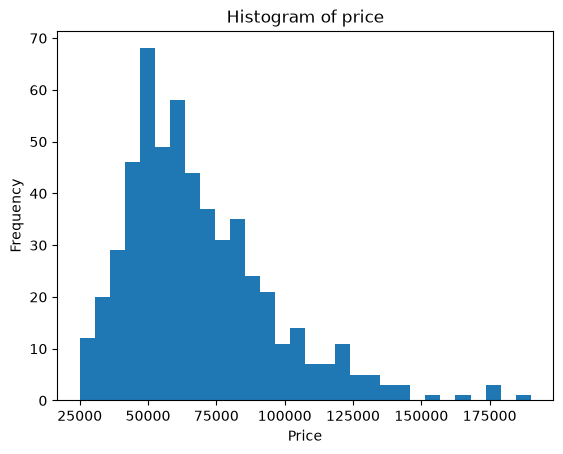

In [11]:
plt.figure()
plt.hist(data['price'], bins=30)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Histogram of price')
plt.show()

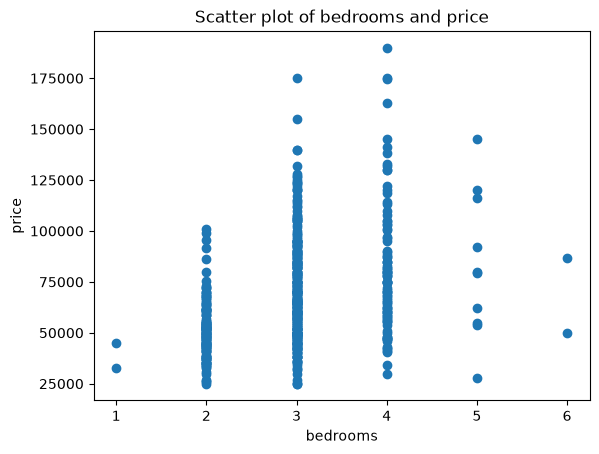

In [12]:
plt.figure()
plt.scatter(data['bedrooms'], data['price'])
plt.xlabel('bedrooms')
plt.ylabel('price')
plt.title('Scatter plot of bedrooms and price')
plt.show()

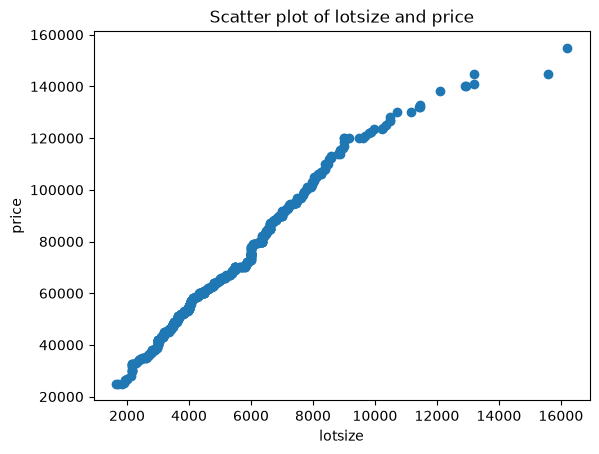

In [13]:
plt.figure()
plt.scatter(data['lotsize'], data['price'])
plt.xlabel('lotsize')
plt.ylabel('price')
plt.title('Scatter plot of lotsize and price')
plt.show()

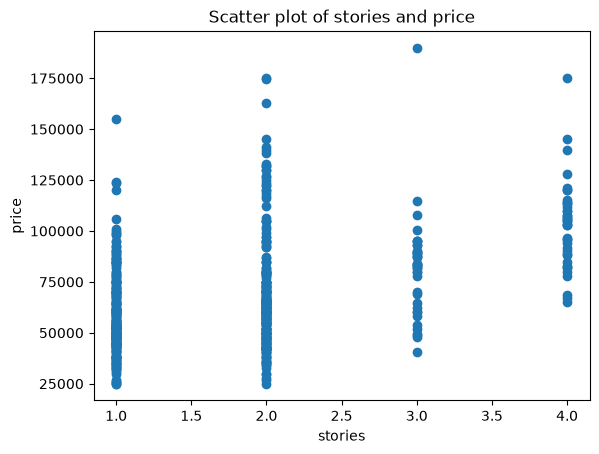

In [14]:
plt.figure()
plt.scatter(data['stories'], data['price'])
plt.xlabel('stories')
plt.ylabel('price')
plt.title('Scatter plot of stories and price')
plt.show()

In [15]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,233,25000,1650.0,3,1,2,yes,no,no,no,no,0.0,no
1,163,25000,1700.0,3,1,1,no,no,no,no,no,0.0,no
2,56,25000,1836.0,2,1,1,yes,no,no,no,no,0.0,no
3,57,25245,1905.0,3,1,1,no,NaN,no,no,no,0.0,no
4,239,26000,1950.0,2,1,1,yes,no,yes,no,no,2.0,no


In [16]:
target_column = 'price'
numeric_cols = ['lotsize', 'bedrooms', 'bathrms', 'stories', 'garagepl'] 
categorical_cols = ['driveway', 'recroom', 'fullbase', 'gashw', 'airco', 'prefarea']

In [17]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,233,25000,1650.0,3,1,2,yes,no,no,no,no,0.0,no
1,163,25000,1700.0,3,1,1,no,no,no,no,no,0.0,no
2,56,25000,1836.0,2,1,1,yes,no,no,no,no,0.0,no
3,57,25245,1905.0,3,1,1,no,NaN,no,no,no,0.0,no
4,239,26000,1950.0,2,1,1,yes,no,yes,no,no,2.0,no


In [18]:
all_used_cols = numeric_cols + categorical_cols + [target_column]
data = data[all_used_cols]

data.head()

,lotsize,bedrooms,bathrms,stories,garagepl,driveway,recroom,fullbase,gashw,airco,prefarea,price
0,1650.0,3,1,2,0.0,yes,no,no,no,no,no,25000
1,1700.0,3,1,1,0.0,no,no,no,no,no,no,25000
2,1836.0,2,1,1,0.0,yes,no,no,no,no,no,25000
3,1905.0,3,1,1,0.0,no,NaN,no,no,no,no,25245
4,1950.0,2,1,1,2.0,yes,no,yes,no,no,no,26000


Factorize

In [19]:
data_factorized = data.copy()
factorize_maps = {}
for col in categorical_cols:
  codes, uniques = pd.factorize(data_factorized[col])
  data_factorized[col] = codes
  factorize_maps[col] = list(uniques)

data_factorized[categorical_cols].head()

,driveway,recroom,fullbase,gashw,airco,prefarea
0,0,0,0,0,0,0
1,1,0,0,0,0,0
2,0,0,0,0,0,0
3,1,-1,0,0,0,0
4,0,0,1,0,0,0


factorize_maps

In [20]:
{'driveway': ['no', 'yes'], 
 'recroom': ['no', 'yes'], 
 'fullbase': ['no', 'yes'], 
 'gashw': ['no', 'yes'], 
 'airco': ['no', 'yes'], 
 'prefarea': ['no', 'yes']}

{'driveway': ['no', 'yes'],
 'recroom': ['no', 'yes'],
 'fullbase': ['no', 'yes'],
 'gashw': ['no', 'yes'],
 'airco': ['no', 'yes'],
 'prefarea': ['no', 'yes']}

# OHE - One Hot Encoder - One Hot кодирование

In [21]:
data_onehot = pd.get_dummies(data_factorized, columns=categorical_cols, drop_first=True)
data_onehot.head()


,lotsize,bedrooms,bathrms,stories,garagepl,price,driveway_0,driveway_1,recroom_0,recroom_1,fullbase_1,gashw_0,gashw_1,airco_0,airco_1,prefarea_0,prefarea_1
0,1650.0,3,1,2,0.0,25000,True,False,True,False,False,True,False,True,False,True,False
1,1700.0,3,1,1,0.0,25000,False,True,True,False,False,True,False,True,False,True,False
2,1836.0,2,1,1,0.0,25000,True,False,True,False,False,True,False,True,False,True,False
3,1905.0,3,1,1,0.0,25245,False,True,False,False,False,True,False,True,False,True,False
4,1950.0,2,1,1,2.0,26000,True,False,True,False,True,True,False,True,False,True,False


In [22]:
data[categorical_cols].head(10)

,driveway,recroom,fullbase,gashw,airco,prefarea
0,yes,no,no,no,no,no
1,no,no,no,no,no,no
2,yes,no,no,no,no,no
3,no,NaN,no,no,no,no
4,yes,no,yes,no,no,no
5,no,no,no,no,no,no
6,yes,no,no,no,no,no
7,yes,no,no,no,no,no
8,no,no,no,no,no,no
9,yes,no,no,no,no,no


# Масштабирование

1. MinMaxScaler
$$
x' = \frac{x-x_{min}}{x_{max}-x_{min}}
$$
2. StandardScaler
$$
x' = \frac{x_\mu}{\sigma}
$$

In [23]:
num_demo = data[numeric_cols].copy()
mms = MinMaxScaler()
std_scaler = StandardScaler()

num_demo_ms = pd.DataFrame(mms.fit_transform(num_demo), columns=numeric_cols)
num_demo_std = pd.DataFrame(std_scaler.fit_transform(num_demo), columns=numeric_cols)


In [24]:
num_demo.head(10)

,lotsize,bedrooms,bathrms,stories,garagepl
0,1650.0,3,1,2,0.0
1,1700.0,3,1,1,0.0
2,1836.0,2,1,1,0.0
3,1905.0,3,1,1,0.0
4,1950.0,2,1,1,2.0
5,1950.0,2,1,1,1.0
6,2000.0,2,1,1,0.0
7,2015.0,3,1,2,0.0
8,2135.0,5,1,2,0.0
9,2145.0,2,1,1,1.0


In [25]:
num_demo_ms.head(10)

,lotsize,bedrooms,bathrms,stories,garagepl
0,0.000000,0.4,0.0,0.333333,0.000000
1,0.003436,0.4,0.0,0.000000,0.000000
2,0.012784,0.2,0.0,0.000000,0.000000
3,0.017526,0.4,0.0,0.000000,0.000000
4,0.020619,0.2,0.0,0.000000,0.666667
5,0.020619,0.2,0.0,0.000000,0.333333
6,0.024055,0.2,0.0,0.000000,0.000000
7,0.025086,0.4,0.0,0.333333,0.000000
8,0.033333,0.8,0.0,0.333333,0.000000
9,0.034021,0.2,0.0,0.000000,0.333333


In [26]:
num_demo_std.head(10)

,lotsize,bedrooms,bathrms,stories,garagepl
0,-1.615463,0.047235,-0.569495,0.221704,-0.806963
1,-1.592455,0.047235,-0.569495,-0.931157,-0.806963
2,-1.529873,-1.310147,-0.569495,-0.931157,-0.806963
3,-1.498121,0.047235,-0.569495,-0.931157,-0.806963
4,-1.477414,-1.310147,-0.569495,-0.931157,1.515724
5,-1.477414,-1.310147,-0.569495,-0.931157,0.354381
6,-1.454405,-1.310147,-0.569495,-0.931157,-0.806963
7,-1.447503,0.047235,-0.569495,0.221704,-0.806963
8,-1.392283,2.761999,-0.569495,0.221704,-0.806963
9,-1.387681,-1.310147,-0.569495,-0.931157,0.354381


# SimpleImputer
- mean
- median
- most_frequent
- constant

In [27]:
data_impute_demo = data.copy()
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

data_impute_demo[numeric_cols] = num_imputer.fit_transform(data_impute_demo[numeric_cols])
data_impute_demo[categorical_cols] = cat_imputer.fit_transform(data_impute_demo[categorical_cols])
data_impute_demo.isna().sum()


lotsize     0
bedrooms    0
bathrms     0
stories     0
garagepl    0
driveway    0
recroom     0
fullbase    0
gashw       0
airco       0
prefarea    0
price       0
dtype: int64

In [28]:
data.isna().sum()

lotsize     5
bedrooms    0
bathrms     0
stories     0
garagepl    2
driveway    2
recroom     4
fullbase    0
gashw       2
airco       7
prefarea    2
price       0
dtype: int64

In [29]:
data_impute_demo.head(16)

,lotsize,bedrooms,bathrms,stories,garagepl,driveway,recroom,fullbase,gashw,airco,prefarea,price
0,1650.0,3.0,1.0,2.0,0.0,yes,no,no,no,no,no,25000
1,1700.0,3.0,1.0,1.0,0.0,no,no,no,no,no,no,25000
2,1836.0,2.0,1.0,1.0,0.0,yes,no,no,no,no,no,25000
3,1905.0,3.0,1.0,1.0,0.0,no,no,no,no,no,no,25245
4,1950.0,2.0,1.0,1.0,2.0,yes,no,yes,no,no,no,26000
5,1950.0,2.0,1.0,1.0,1.0,no,no,no,no,no,no,26500
6,2000.0,2.0,1.0,1.0,0.0,yes,no,no,no,no,no,27000
7,2015.0,3.0,1.0,2.0,0.0,yes,no,no,no,no,no,27000
8,2135.0,5.0,1.0,2.0,0.0,no,no,no,no,no,no,28000
9,2145.0,2.0,1.0,1.0,1.0,yes,no,no,no,no,no,30000


# Feature Engineering

In [30]:
data_fe = data.copy()
data_fe['rooms_total'] = data_fe['bedrooms'] + data_fe['bathrms']
data_fe['lot_per'] = data_fe['lotsize'] / np.where(data_fe['rooms_total'] > 0, data_fe['rooms_total'],1)
data_fe[['lotsize', 'bedrooms', 'bathrms', 'rooms_total', 'lot_per']].head()

,lotsize,bedrooms,bathrms,rooms_total,lot_per
0,1650.0,3,1,4,412.50
1,1700.0,3,1,4,425.00
2,1836.0,2,1,3,612.00
3,1905.0,3,1,4,476.25
4,1950.0,2,1,3,650.00


In [31]:
X = data_fe.drop(columns=[target_column])
y = data_fe[target_column]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_features = numeric_cols + ['rooms_total', 'lot_per']
cat_features = categorical_cols

numeric_transformer = Pipeline(

    steps=[

        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())

    ]


)


categorical_transformer = Pipeline(

    steps = [

('imputer', SimpleImputer(strategy='most_frequent')),
('onehot', OneHotEncoder())


]

)



preprocessor = ColumnTransformer(

    transformers=[
        ('num', numeric_transformer, num_features),
        ('cat', categorical_transformer, cat_features)]

)



linreg_model = Pipeline(

    steps=[

        ('prepocessor', preprocessor),
        ('model', LinearRegression())
    

    ]

)



linreg_model.fit(X_train, y_train)
y_pred = linreg_model.predict(X_test)


In [32]:
y_test, y_pred

(316     67000
 77      43000
 360     73000
 90      44900
 495    106000
         ...  
 357     73000
 39      37900
 54      40500
 155     50000
 46      38000
 Name: price, Length: 110, dtype: int64,
 array([ 69971.61522612,  40512.80945026,  72740.94466901,  45060.23405556,
        106395.94907287,  53209.84222357,  49854.23529107,  57885.96828537,
        122798.89467581,  93956.4993576 ,  22907.97526081, 106618.20369069,
         86998.48601954,  88752.90020131, 119342.62886426, 102437.20355763,
        105792.13019713,  38419.69927742,  93403.7608335 , 106115.68579198,
         37700.74839279,  48113.14472623, 162316.07480799,  57860.38895303,
         64319.60317685,  20476.41773591,  93782.22737173,  50379.23905945,
         38070.21552046, 108973.88396807,  46844.77668926,  82079.73331569,
         39958.53107565,  95285.53112522, 102686.44206448,  64240.18814105,
         59824.40443109,  84847.39653323,  83554.08979535, 117129.41308975,
         49467.63094095,  73993.07

# Metrics

# MAE - Mean Absolute Error
$$
MAE = \frac{1}{n}\sum|y_i - \hat{y_i}|
$$
# MSE - Mean Squared Error
$$
MSE = \frac{1}{n}\sum(y_i - \hat{y_i})^2
$$
# RMSE - Root Mean Squared Error
$$
RMSE = \sqrt{MSE}
$$
# $R^2$ Score
$$
R^2 = 1 - \frac{\text{Ошибка нашей модели}}{\text{ошибка модели, которая всегда предсказывает среднее}}
$$

# Metrics (MAE, MSE, RMSE, R2_Score)


In [33]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


print(f'''

MAE: {mae:.3f}
MSE: {mse:.3f}
RMSE: {rmse:.3f}
R2: {r2:.3f}


'''

)



MAE: 4824.592
MSE: 97131140.756
RMSE: 9855.513
R2: 0.892





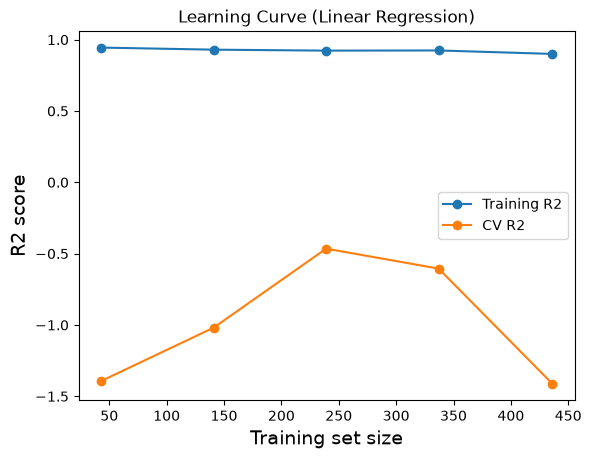

In [34]:
train_sizes, train_scores, test_scores = learning_curve(
    linreg_model,
    X,
    y,
    cv=5,
    scoring='r2',
    train_sizes=np.linspace(.1, 1.0, 5),
    n_jobs=None,
    shuffle=True,
    random_state=42)

train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

plt.figure()
plt.plot(train_sizes, train_mean, label='Training R2', marker='o')
plt.plot(train_sizes, test_mean, 'o-', label='CV R2', )
plt.title('Learning Curve (Linear Regression)')
plt.ylabel('R2 score', fontsize=14)
plt.xlabel('Training set size', fontsize=14)
plt.legend(loc='best')
plt.show()